# ROMY vs ADR Comparison Plot

This notebook loads ROMY and ADR data for a specified event and creates comparison plots showing:
- Waveforms for JZ, JN, JE components
- Residuals in percent deviation
- Cross-correlation values


## Notebook Overview
This notebook compares ROMY recordings against ADR-derived products across events and summarizes agreement metrics.

**Main workflow**
- Load paired ROMY and ADR datasets per event.
- Align and preprocess comparable components.
- Compute correlation/misfit metrics (e.g., CC, RMSE, TF metrics).
- Generate comparison figures.
- Save tabulated results to output files.

## Imports

In [227]:
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from obspy.signal.cross_correlation import correlate, xcorr_max
from sixdegrees.sixdegrees import sixdegrees

## Configuration

In [228]:
# set event date
# event date = '20190514' # no data

# event_date = '20230908'
# event_date = '20230912' # bad Z with jump
# event_date = '20231202'
# event_date = '20231203' # no data

# event_date = '20240314'
# event_date = '20240322'
# event_date = '20240323'
# event_date = '20240414'
# event_date = '20240422'
# event_date = '20240815'
# event_date = '20241023'
# event_date = '20240915'

# event_date = '20250602'
# event_date = '20250513'
# event_date = '20251206'
# event_date = '20251212'
# event_date = '20251227'

# event_date = '20260107'
event_date = '20260420'

# set fmin and fmax
fmin = 0.02
fmax = 0.1


## Load ROMY Data

In [229]:
print(f"Loading ROMY data for event {event_date}...")

# Try config_romy_<date>.yml first, then config_<date>.yml
romy_config_path = f"./events/event_{event_date}/config_romy_{event_date}.yml"
if not os.path.exists(romy_config_path):
    romy_config_path = f"./events/event_{event_date}/config_{event_date}.yml"

if not os.path.exists(romy_config_path):
    raise FileNotFoundError(f"ROMY config file not found: {romy_config_path}")

# Load ROMY configuration
romy_config = sixdegrees.load_from_yaml(romy_config_path)

romy_config['verbose'] = True

# Setup ROMY sixdegrees object
sd_romy = sixdegrees(conf=romy_config)

# Load ROMY data
# sd_romy.load_data(romy_config['tbeg'], romy_config['tend'], resample_rate=5)
sd_romy.load_data(romy_config['tbeg'], romy_config['tend'])

# Ensure all traces have the same amount of samples
sd_romy.trim_stream(set_common=True, set_interpolate=True)

# Filter data
sd_romy.filter_data(fmin=fmin, fmax=fmax, output=False)

# Apply polarity correction if needed
if 'pol_dict' in romy_config:
    sd_romy.polarity_stream(pol_dict=romy_config['pol_dict'], raw=True)
else:
    # Default polarity correction
    sd_romy.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

# Cut bad data if specified
if 'time_cuts' in romy_config:
    for key, values in romy_config['time_cuts'].items():
        for value in values:
            sd_romy.replace_values_in_window(
                tbeg=value[0], tend=value[1], 
                value=0, channel_list=[key]
            )

sd_romy.st.trim(UTCDateTime(romy_config['tbeg']), UTCDateTime(romy_config['tend']), nearest_sample=False)

print(sd_romy.st)

print(f"ROMY data loaded successfully")
print(f"ROMY channels: {[tr.id for tr in sd_romy.st]}")

Loading ROMY data for event 20260420...
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
XX.ROMY..BHN | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
XX.ROMY..BHE | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BJZ | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
XX.ROMY..BJN | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
XX.ROMY..BJE | 2026-04-20T08:04:59.003401Z - 2026-04-20T09:00:00.953401Z | 20.0 Hz, 66040 samples
 -> trim_stream: window 2026-04-20T08:04:59.003401Z 

## Load ADR Data

In [230]:
print(f"Loading ADR data for event {event_date}...")

# Try config_adr_<date>.yml first, then check if ADR mseed file exists
adr_config_path = f"./events/event_{event_date}/config_adr_{event_date}.yml"

# Load existing ADR config
adr_config = sixdegrees.load_from_yaml(adr_config_path)

# Setup ADR sixdegrees object
sd_adr = sixdegrees(conf=adr_config)

# Load ADR data
# sd_adr.load_data(romy_config['tbeg'], adr_config['tend'], resample_rate=5)
sd_adr.load_data(romy_config['tbeg'], adr_config['tend'])

# Ensure all traces have the same amount of samples
sd_adr.trim_stream(set_common=True, set_interpolate=False)

# Filter data
sd_adr.filter_data(fmin=fmin, fmax=fmax, output=False)

if 'time_cuts' in romy_config:
    for key, values in romy_config['time_cuts'].items():
        for value in values:
            sd_romy.replace_values_in_window(
                tbeg=value[0], tend=value[1], 
                value=0, channel_list=[key]
            )

# Trim ADR data to same length as ROMY data
sd_adr.st.trim(UTCDateTime(romy_config['tbeg']), UTCDateTime(romy_config['tend']), nearest_sample=False)

print(f"ADR data loaded successfully")
print(f"ADR channels: {[tr.id for tr in sd_adr.st]}")

Loading ADR data for event 20260420...


ADR data loaded successfully
ADR channels: ['GR.FUR..BHE', 'GR.FUR..BHN', 'GR.FUR..BHZ', 'GR.FUR..BJZ', 'GR.FUR..BJN', 'GR.FUR..BJE']


## Extract Traces and Prepare Data

In [231]:
# Synchronize ROMY and ADR onto a common sample grid (linear interpolation).

all_traces = list(sd_romy.st) + list(sd_adr.st)
sync_starttime = max(tr.stats.starttime for tr in all_traces)
sync_endtime = min(tr.stats.endtime for tr in all_traces)
sync_rate = sd_romy.st[0].stats.sampling_rate

for st in (sd_romy.st, sd_adr.st):
    st.interpolate(sampling_rate=sync_rate, method="linear", starttime=sync_starttime)
    st.trim(starttime=sync_starttime, endtime=sync_endtime, nearest_sample=False)

sync_npts = sd_romy.st[0].stats.npts

print(f"ROMY (master): {sync_starttime} - {sync_endtime} @ {sync_rate} Hz, npts={sync_npts}")
print("After sync:")
for tr in list(sd_romy.st) + list(sd_adr.st):
    print(f"  {tr.id:20s}  start={tr.stats.starttime}  npts={tr.stats.npts}  dt={tr.stats.delta}")

ROMY (master): 2026-04-20T08:05:00.003401Z - 2026-04-20T08:59:59.953401Z @ 20.0 Hz, npts=65999
After sync:
  XX.ROMY..BHZ          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  XX.ROMY..BHN          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  XX.ROMY..BHE          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  XX.ROMY..BJZ          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  XX.ROMY..BJN          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  XX.ROMY..BJE          start=2026-04-20T08:05:00.003401Z  npts=65999  dt=0.05
  GR.FUR..BHE           start=2026-04-20T08:05:00.003401Z  npts=66000  dt=0.05
  GR.FUR..BHN           start=2026-04-20T08:05:00.003401Z  npts=66000  dt=0.05
  GR.FUR..BHZ           start=2026-04-20T08:05:00.003401Z  npts=66000  dt=0.05
  GR.FUR..BJZ           start=2026-04-20T08:05:00.003401Z  npts=66000  dt=0.05
  GR.FUR..BJN           start=2026-04-20T08:05:00.003401Z  npts=66000  dt=0.05
  GR.FUR..BJE           

In [232]:
# Components to compare
components = ['JZ', 'JN', 'JE']

# Extract traces for each component
romy_traces = {}
adr_traces = {}

for comp in components:
    # Get ROMY trace
    romy_tr = sd_romy.st.select(channel=f"*{comp}")
    romy_tr = romy_tr.taper(0.1, type='cosine')
    if len(romy_tr) > 0:
        romy_traces[comp] = romy_tr[0]
    else:
        print(f"Warning: ROMY trace for {comp} not found")
        romy_traces[comp] = None
    
    # Get ADR trace
    adr_tr = sd_adr.st.select(channel=f"*{comp}")
    adr_tr = adr_tr.taper(0.1, type='cosine')
    if len(adr_tr) > 0:
        adr_traces[comp] = adr_tr[0]
    else:
        print(f"Warning: ADR trace for {comp} not found")
        adr_traces[comp] = None

# Get origin time for time axis
origin_time = UTCDateTime(romy_config['tbeg'])

# Get time arrays relative to origin time
if romy_traces['JZ'] is not None:
    times_romy = (np.array(romy_traces['JZ'].times()) + 
                  (romy_traces['JZ'].stats.starttime - origin_time)) / 3600.0  # Convert to hours
else:
    times_romy = None

## Compute Cross-Correlation and Residuals

In [233]:
# Function to compute cross-correlation
def compute_cc(trace1, trace2):
    """Compute cross-correlation between two traces."""
    if trace1 is None or trace2 is None:
        return None, None, None
    
    if trace1.stats.sampling_rate != trace2.stats.sampling_rate:
        print(f"Warning: Sampling rates are different for {trace1.id} and {trace2.id}")
        return None, None, None
    else:
        sps = trace1.stats.sampling_rate
    
    # Ensure same length
    min_len = min(len(trace1.data), len(trace2.data))
    data1 = trace1.data[:min_len]
    data2 = trace2.data[:min_len]
    
    # Normalize data
    data1_norm = (data1 - np.mean(data1)) / (np.std(data1) + 1e-10)
    data2_norm = (data2 - np.mean(data2)) / (np.std(data2) + 1e-10)
    
    # Compute cross-correlation
    shift_len = len(data1_norm)
    corr = correlate(data1_norm, data2_norm, shift=shift_len)
    
    # Get maximum correlation
    shift_max, cc_max = xcorr_max(corr)
    
    # Get zero-shift correlation
    corr_zero = correlate(data1_norm, data2_norm, shift=0)
    shift_zero, cc_zero = xcorr_max(corr_zero)
    
    return cc_max, shift_max/sps, cc_zero

In [234]:
# Function to compute deviation
def compute_deviation(trace1, trace2):
    """ Compute deviation between two traces. """
    from scipy.signal import hilbert
    
    if trace1 is None or trace2 is None:
        return None, None
    
    # Ensure same length
    min_len = min(len(trace1.data), len(trace2.data))
    data1 = trace1.data[:min_len]
    data2 = trace2.data[:min_len]
    
    data1_env = np.abs(hilbert(data1))
    data2_env = np.abs(hilbert(data2))

    # dev = np.where(data1_env > 1e-9, abs(data2_env - data1_env) / data1_env * 100, 0)
    dev = abs(data2_env - data1_env) / max(data1_env) * 100

    return dev

In [235]:

# Compute cross-correlation and residuals for each component
cc_results = {}
deviations = {}

for comp in components:
    romy_tr = romy_traces[comp]
    adr_tr = adr_traces[comp]
    
    if romy_tr is not None and adr_tr is not None:
        # Compute cross-correlation
        cc_max, shift_max, cc_zero = compute_cc(romy_tr, adr_tr)
        cc_results[comp] = {
            'cc_max': cc_max,
            'shift_max': shift_max,
            'cc_zero': cc_zero
        }
        
        # Compute absolute deviation and envelope
        dev = compute_deviation(romy_tr, adr_tr)
        deviations[comp] = dev
        
        print(f"{comp}: CC_max={cc_max:.2f} ({shift_max:.2f} s), CC_zero={cc_zero:.2f}")
    else:
        cc_results[comp] = None
        deviations[comp] = None


JZ: CC_max=0.95 (-0.05 s), CC_zero=0.95
JN: CC_max=0.98 (-0.35 s), CC_zero=0.97
JE: CC_max=0.98 (-0.50 s), CC_zero=0.96


## Create Comparison Plot

Saved: ./events/event_20260420/figures/20260420_romy_adr_comparison.png


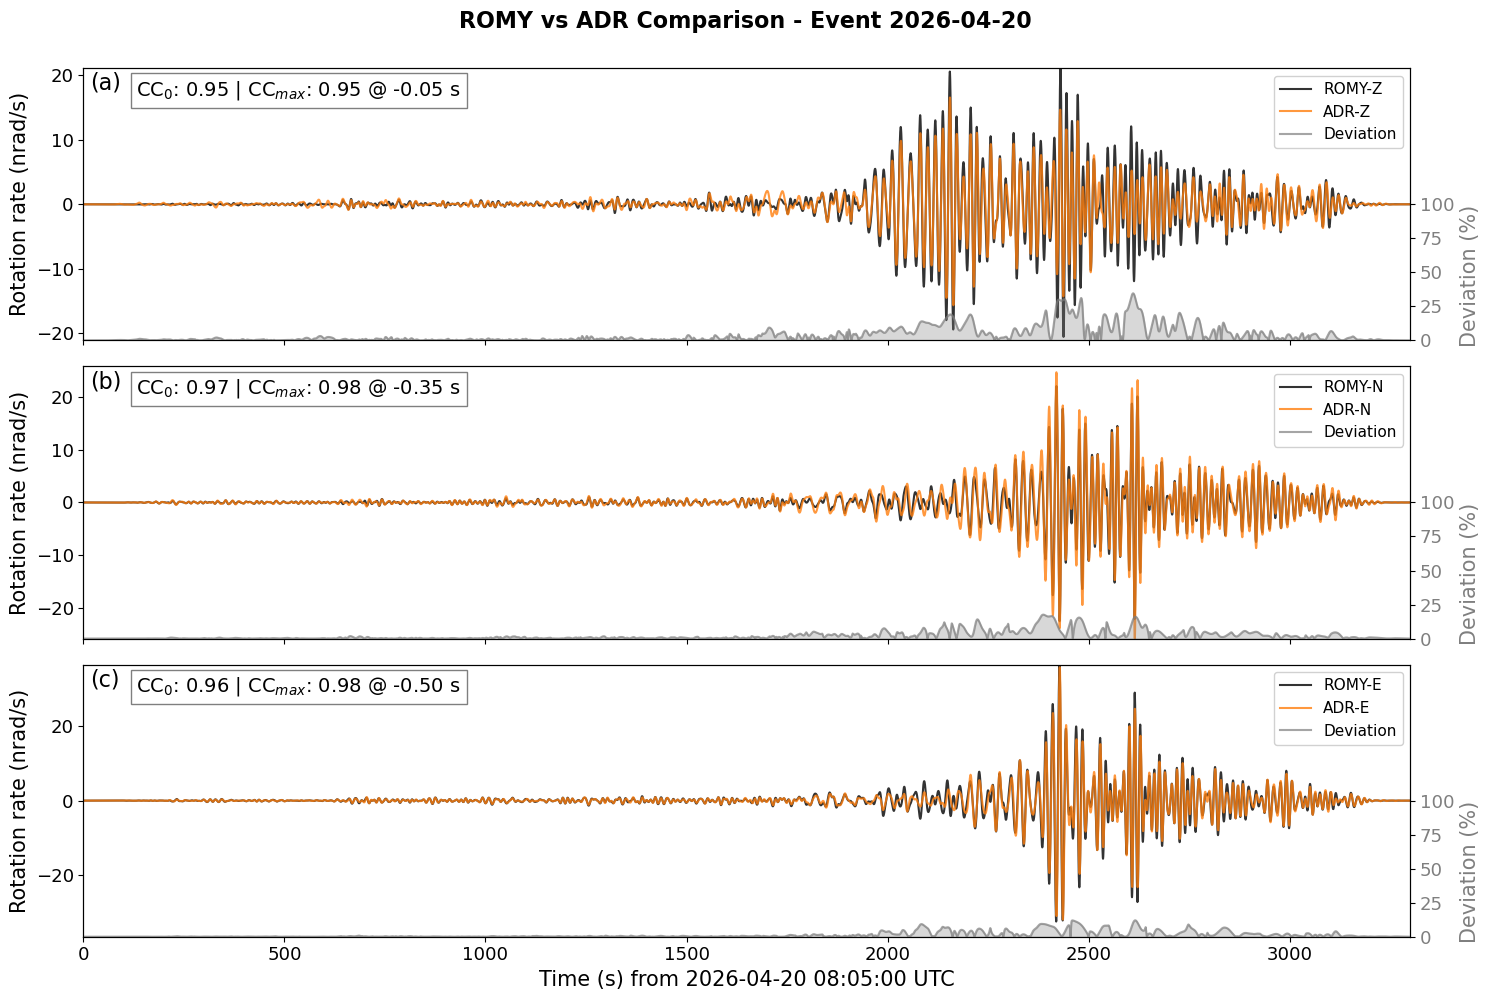

In [236]:
# Create figure with subplots: 3 rows (one for each component), full width
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

plt.subplots_adjust(hspace=0.01)

yscale = 1e9
yunit = 'nrad/s'

fs = 15

# Colors for ROMY and ADR
color_romy = 'black'
color_adr = 'tab:orange'
color_dev = 'tab:gray'

# Plot each component
for i, comp in enumerate(components):
    romy_tr = romy_traces[comp]
    adr_tr = adr_traces[comp]
    
    if romy_tr is None or adr_tr is None:
        continue
    
    # Get time arrays
    times_romy_comp = romy_tr.times()
    times_adr_comp = adr_tr.times()
    
    # Ensure same length for plotting
    min_len = min(len(times_romy_comp), len(times_adr_comp))
    times_plot = times_romy_comp[:min_len]
    
    # Main axis for waveforms
    ax = axes[i]
    
    # Plot ROMY waveform on left y-axis
    line1 = ax.plot(times_plot, romy_tr.data[:min_len]*yscale, 
                    color=color_romy, linewidth=1.5, alpha=0.8, label=f'ROMY-{comp[1]}')
    
    # Plot ADR waveform on left y-axis
    line2 = ax.plot(times_plot, adr_tr.data[:min_len]*yscale, 
                    color=color_adr, linewidth=1.5, alpha=0.8, label=f'ADR-{comp[1]}')
    
    # Add cross-correlation info
    if cc_results[comp] is not None:
        cc_max = cc_results[comp]['cc_max']
        cc_zero = cc_results[comp]['cc_zero']
        shift_max = cc_results[comp]['shift_max']
        maxstr = r"$_{max}$"
        info_text = f'CC$_{0}$: {cc_zero:.2f} | CC{maxstr}: {cc_max:.2f} @ {shift_max:.2f} s'
        ax.text(0.04, 0.96, info_text, 
                transform=ax.transAxes, 
                fontsize=fs-1, verticalalignment='top',
                bbox=dict(facecolor='white', alpha=0.5))
    
    # Set left y-axis properties
    ax.set_ylabel(f'Rotation rate ({yunit})', fontsize=fs, color='black')
    # ax.set_title(f'{comp} Component', fontsize=fs, fontweight='bold')
    ax.tick_params(axis='y', labelcolor='black')
    # ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xlim(left=0)
    
    # set y-axis limits from min max of both traces
    ymax = max(max(abs(romy_tr.data[:min_len])), max(abs(adr_tr.data[:min_len])))
    ax.set_ylim(bottom=-ymax*yscale, top=ymax*yscale)
    # Create second y-axis for absolute deviation (on the right)
    ax2 = ax.twinx()
    
    if deviations[comp] is not None:
        # Plot absolute deviation
        line3 = ax2.plot(times_plot, deviations[comp][:min_len], 
                        color=color_dev, linewidth=1.5, alpha=0.7,
                        # label=f'(|ADR| - |ROMY|) / max(|ROMY|) * 100'
                        label=f"Deviation"
                        )
        ax2.fill_between(times_plot, deviations[comp][:min_len], color=color_dev, alpha=0.3)
        ax2.set_ylim(bottom=0)
        ax2.set_ylim(top=200)
        ax2.set_yticks(np.linspace(0, 100, 5))
        ax2.set_yticklabels([f'{int(y)}' for y in np.linspace(0, 100, 5)])

    # Set right y-axis properties
    ax2.set_ylabel('Deviation (%)', fontsize=fs, color=color_dev, ha='right')
    ax2.tick_params(axis='y', labelcolor=color_dev, labelsize=fs-2)
    
    # Combine legends from both axes
    lines = line1 + line2
    if deviations[comp] is not None:
        lines += line3
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', fontsize=fs-4, framealpha=0.9)

for _ax, label in zip(axes, ["(a)", "(b)", "(c)"]):
    _ax.set_xlim(0, max(times_romy_comp))
    _ax.text(0.005, 0.92, label, fontsize=fs+1, transform=_ax.transAxes)
    _ax.tick_params(axis='both', labelsize=fs-2)

axes[2].set_xlabel(f'Time (s) from {origin_time.strftime("%Y-%m-%d %H:%M:%S")} UTC', fontsize=fs)


# Add overall title
fig.suptitle(f'ROMY vs ADR Comparison - Event {UTCDateTime(event_date).strftime("%Y-%m-%d")}', 
             fontsize=16, fontweight='bold', y=0.995)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.99])

# Save figure
output_file = os.path.join(f'./events/event_{event_date}/figures/{event_date}_romy_adr_comparison.png')
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Saved: {output_file}")

plt.show()

### TF Misfit

In [12]:
from obspy.signal.tf_misfit import pm, em, plot_tf_misfits

dt = romy_tr.stats.delta

yscale = 1e9

# Compute TF misfit
# plot_tfr(romy_tr.data*yscale, dt=dt, fmin=fmin, fmax=fmax)

pm(romy_tr.data*yscale, adr_tr.data*yscale, dt=dt, fmin=fmin, fmax=fmax)


0.09239484528470598

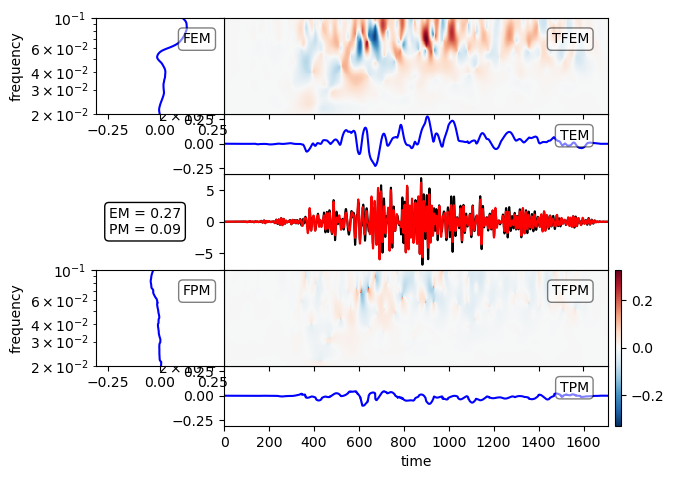

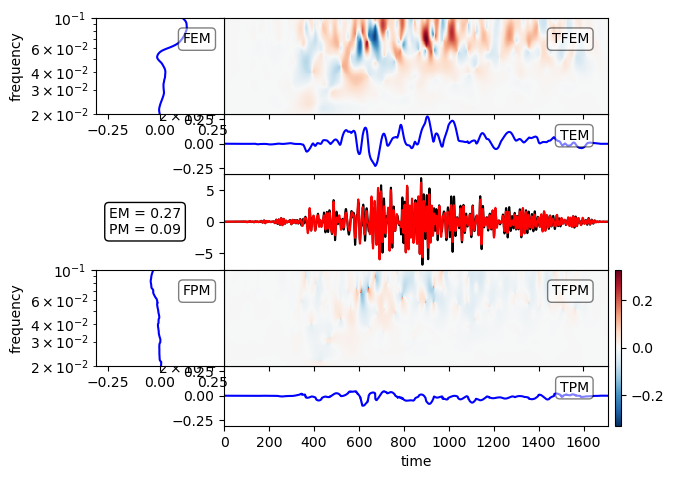

In [13]:

plot_tf_misfits(romy_tr.data*yscale, adr_tr.data*yscale, dt=dt, fmin=fmin, fmax=fmax, show=False)



### Write to Output File

In [14]:
## Save Results to DataFrame

# Create results directory if it doesn't exist
results_dir = "./output"
os.makedirs(results_dir, exist_ok=True)

# Prepare data for dataframe
results_data = []
for comp in components:
    if cc_results[comp] is not None and deviations[comp] is not None:
        maxdev = np.max(deviations[comp])
        results_data.append({
            'event': event_date,
            'component': comp,
            'ccmax': round(cc_results[comp]['cc_max'], 2),
            'cczero': round(cc_results[comp]['cc_zero'], 2),
            'ccmaxshift': round(cc_results[comp]['shift_max'], 2),
            'maxdev': round(maxdev, 2),
            'n_stations': len(adr_config['stations']),
            'fmin': fmin, 
            'fmax': fmax,
        })

# Create dataframe
df_new = pd.DataFrame(results_data)

# Load existing results if they exist
results_file = os.path.join(results_dir, 'romy_adr_comparison_results.csv')
if os.path.exists(results_file):
    df_existing = pd.read_csv(results_file)
    # Ensure event column is string type for consistent comparison
    df_existing['event'] = df_existing['event'].astype(str)
    df_new['event'] = df_new['event'].astype(str)
    
    # Remove rows that match both event and component (overwrite existing)
    # Create a MultiIndex for efficient filtering
    df_existing_indexed = df_existing.set_index(['event', 'component'])
    df_new_indexed = df_new.set_index(['event', 'component'])
    
    # Drop rows from existing that match new data
    df_existing_indexed = df_existing_indexed.drop(df_new_indexed.index, errors='ignore')
    
    # Reset index and append new results
    df_existing = df_existing_indexed.reset_index()
    df_final = pd.concat([df_existing, df_new], ignore_index=True)
else:
    df_final = df_new

# Save to CSV
df_final.to_csv(results_file, index=False)
print(f"Results saved to: {results_file}")
print(f"Total events in results: {df_final['event'].nunique()}")
print(f"\nResults for event {event_date}:")
print(df_new.to_string(index=False))

Results saved to: ./output/romy_adr_comparison_results.csv
Total events in results: 17

Results for event 20230908:
   event component  ccmax  cczero  ccmaxshift  maxdev  n_stations  fmin  fmax
20230908        JZ   0.95    0.95         0.2   37.76           6  0.02   0.1
20230908        JN   0.99    0.97         0.4   12.68           6  0.02   0.1
20230908        JE   0.94    0.93         0.2   28.85           6  0.02   0.1


In [15]:
df = pd.read_csv("./output/romy_adr_comparison_results.csv")
df["event"] = df["event"].astype(str)

baz = pd.read_csv("./output/results_backazimuth.csv")
baz["event_date"] = baz["event_date"].astype(str)

# Keep one row per event (these columns are constant per event)
baz_per_event = (
    baz[["event_date", "origin_time", "magnitude", "distance_km", "backazimuth_theoretical"]]
    .drop_duplicates(subset="event_date")
    .rename(columns={"event_date": "event", "backazimuth_theoretical": "backazimuth"})
)

df = df.merge(baz_per_event, on="event", how="left")

df

,event,component,ccmax,cczero,ccmaxshift,maxdev,n_stations,fmin,fmax,origin_time,magnitude,distance_km,backazimuth
0,20240323,JZ,0.76,0.72,1.0,55.27,3.0,0.02,0.1,2024-03-23T20:22:04.348000Z,6.9,13331.88,58.74
1,20240323,JN,0.74,0.74,0.2,65.63,3.0,0.02,0.1,2024-03-23T20:22:04.348000Z,6.9,13331.88,58.74
2,20240323,JE,0.91,0.90,-0.4,36.63,3.0,0.02,0.1,2024-03-23T20:22:04.348000Z,6.9,13331.88,58.74
3,20240414,JZ,0.82,0.81,0.4,88.13,5.0,0.02,0.1,2024-04-14T20:56:28.201000Z,6.5,13978.50,51.99
4,20240414,JN,0.95,0.95,0.0,17.75,5.0,0.02,0.1,2024-04-14T20:56:28.201000Z,6.5,13978.50,51.99
5,20240414,JE,0.96,0.95,-0.4,19.03,5.0,0.02,0.1,2024-04-14T20:56:28.201000Z,6.5,13978.50,51.99
6,20240422,JZ,0.48,0.48,0.0,151.49,5.0,0.02,0.1,2024-04-22T18:26:52.852000Z,6.1,9470.32,59.40
7,20240422,JN,0.95,0.95,0.0,51.66,5.0,0.02,0.1,2024-04-22T18:26:52.852000Z,6.1,9470.32,59.40
8,20240422,JE,0.95,0.94,-0.4,39.51,5.0,0.02,0.1,2024-04-22T18:26:52.852000Z,6.1,9470.32,59.40
9,20240815,JZ,0.89,0.89,0.0,36.03,5.0,0.02,0.1,2024-08-15T23:35:53.943000Z,6.1,9474.15,59.31


In [16]:
df = pd.read_csv("./output/romy_adr_comparison_results.csv")



In [17]:
components = ["JZ", "JN", "JE"]
for comp in components:
    df2 = df[df["component"] == comp]
    print(comp, df2["ccmaxshift"].max())

JZ 1.0
JN 0.8
JE 8.6


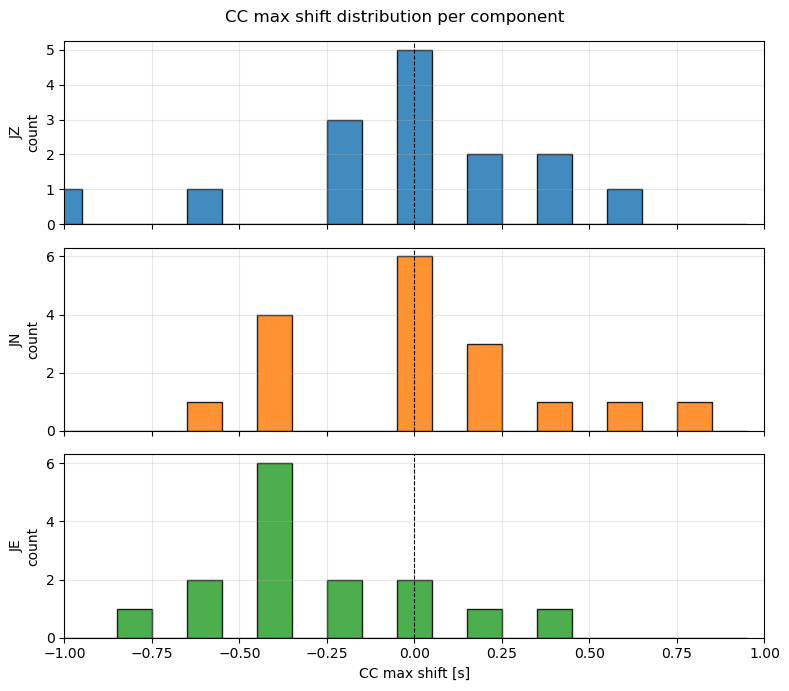

In [18]:
import matplotlib.pyplot as plt
import numpy as np

components = ["JZ", "JN", "JE"]
colors = {"JZ": "tab:blue", "JN": "tab:orange", "JE": "tab:green"}
bins = np.arange(-1.05, 1.05, 0.1)

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax, comp in zip(axes, components):
    data = df.loc[df["component"] == comp, "ccmaxshift"]
    ax.hist(data, bins=bins, color=colors[comp], edgecolor="black", alpha=0.85)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.set_ylabel(f"{comp}\ncount")
    ax.grid(alpha=0.3)
    ax.set_xlim(-1, 1)

axes[-1].set_xlabel("CC max shift [s]")
fig.suptitle("CC max shift distribution per component")
plt.tight_layout()
plt.show()

In [19]:
plt.scatter(df["backazimuth"], df["ccmaxshift"])

plt.ylim(-1, 1)

KeyError: 'backazimuth'